In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import os

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import RandomizedSearchCV

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

data_path = "/kaggle/input/notebooks/ahmadlmomani/1-random-forest-hyperparameter-tuning/processed_data"

X_train = pd.read_csv(f"{data_path}/X_train.csv")
X_test = pd.read_csv(f"{data_path}/X_test.csv")

y_train = pd.read_csv(f"{data_path}/y_train.csv").squeeze("columns")
y_test = pd.read_csv(f"{data_path}/y_test.csv").squeeze("columns")

print("Data loaded successfully!")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)


Data loaded successfully!
X_train: (8929, 15)
X_test: (2233, 15)


In [3]:

numerical_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object']
).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

print("Preprocessor created successfully!")


Preprocessor created successfully!


In [4]:

rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])

print("Random Forest Pipeline created successfully!")


Random Forest Pipeline created successfully!


In [5]:

param_distributions = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [None, 10, 20],
    'classifier__max_features': ['sqrt', 'log2'],
    'classifier__min_samples_split': [2, 5],
    'classifier__criterion': ['gini', 'entropy']
}

print("Total possible combinations:",
      np.prod([len(v) for v in param_distributions.values()]))


Total possible combinations: 48


In [6]:

random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=25,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    random_state=42,
    verbose=2,
    refit=True
)

start_time = time.time()

random_search.fit(X_train, y_train)

random_search_time = time.time() - start_time

print("\nRandomized Search completed successfully!")
print(f"Total Search Time: {random_search_time:.2f} seconds")


Fitting 5 folds for each of 25 candidates, totalling 125 fits

Randomized Search completed successfully!
Total Search Time: 76.61 seconds


In [7]:

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation F1-Score:")
print(f"{random_search.best_score_:.4f}")


Best Parameters:
{'classifier__n_estimators': 200, 'classifier__min_samples_split': 5, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 20, 'classifier__criterion': 'gini'}

Best Cross-Validation F1-Score:
0.6934


In [8]:

best_rf_model = random_search.best_estimator_

start_time = time.time()

y_pred_random = best_rf_model.predict(X_test)

random_prediction_time = time.time() - start_time

random_accuracy = accuracy_score(y_test, y_pred_random)
random_precision = precision_score(y_test, y_pred_random)
random_recall = recall_score(y_test, y_pred_random)
random_f1 = f1_score(y_test, y_pred_random)

print("Random Forest - Randomized Search Results")
print("-" * 45)

print(f"Accuracy:  {random_accuracy:.4f}")
print(f"Precision: {random_precision:.4f}")
print(f"Recall:    {random_recall:.4f}")
print(f"F1-Score:  {random_f1:.4f}")

print(f"\nSearch Time: {random_search_time:.2f} seconds")
print(f"Prediction Time: {random_prediction_time:.4f} seconds")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_random))


Random Forest - Randomized Search Results
---------------------------------------------
Accuracy:  0.7326
Precision: 0.7665
Recall:    0.6267
F1-Score:  0.6895

Search Time: 76.61 seconds
Prediction Time: 0.1052 seconds

Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.83      0.77      1175
           1       0.77      0.63      0.69      1058

    accuracy                           0.73      2233
   macro avg       0.74      0.73      0.73      2233
weighted avg       0.74      0.73      0.73      2233



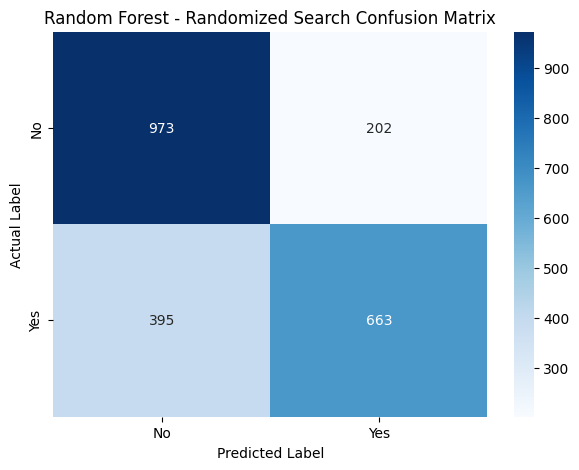

In [9]:

cm_random = confusion_matrix(y_test, y_pred_random)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_random,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No', 'Yes'],
    yticklabels=['No', 'Yes']
)

plt.title("Random Forest - Randomized Search Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()


In [10]:

output_dir = "/kaggle/working/randomized_search_results"
os.makedirs(output_dir, exist_ok=True)

random_results = pd.DataFrame({
    'Model': ['Random Forest Randomized Search'],
    'Accuracy': [random_accuracy],
    'Precision': [random_precision],
    'Recall': [random_recall],
    'F1-Score': [random_f1],
    'Search Time': [random_search_time],
    'Prediction Time': [random_prediction_time],
    'Best CV F1': [random_search.best_score_]
})

random_results.to_csv(
    f"{output_dir}/randomized_search_metrics.csv",
    index=False
)

pd.DataFrame([random_search.best_params_]).to_csv(
    f"{output_dir}/best_parameters.csv",
    index=False
)

pd.DataFrame(
    cm_random,
    index=['Actual_No', 'Actual_Yes'],
    columns=['Predicted_No', 'Predicted_Yes']
).to_csv(
    f"{output_dir}/random_confusion_matrix.csv"
)

pd.DataFrame(random_search.cv_results_).to_csv(
    f"{output_dir}/random_cv_results.csv",
    index=False
)

print("Randomized Search results saved successfully!")

display(random_results)


Randomized Search results saved successfully!


,Model,Accuracy,Precision,Recall,F1-Score,Search Time,Prediction Time,Best CV F1
0,Random Forest Randomized Search,0.732647,0.766474,0.626654,0.689548,76.610195,0.105181,0.69344
